# Clothing Restyle GAN (conditional GAN + discriminator "real vs generated" score)

**What this notebook does**

1. Installs every dependency itself (`%pip`).
2. Downloads the **Fashion-MNIST** clothing dataset from the internet (Zalando Research, GitHub / S3 mirrors).
3. Builds a training set of clothes rendered in many **patterns** (stripes, checks, dots, zig-zag, gradients, blobs) and **colours**.
4. Trains a **conditional U-Net generator** that takes *a clothing image* + a *style code* (pattern, two colours, angle, scale) and outputs the **same garment with a new design / pattern / colour**.
5. Trains a **discriminator** whose score (0 to 1) says whether an image looks **REAL** or **GENERATED**. A decision threshold is calibrated on held-out data.
6. Saves the models and starts a small **local Flask web app** (`http://127.0.0.1:5000`) where you upload a clothing picture, get restyled variants, and see the discriminator score for each.

Run the cells top to bottom. A GPU makes training much faster, but the default settings also work on CPU (slowly).

In [2]:
# 1) Dependencies - installed from inside the notebook
%pip install -q torch numpy matplotlib pillow flask

Note: you may need to restart the kernel to use updated packages.



[notice] A new release of pip is available: 24.0 -> 26.3
[notice] To update, run: python.exe -m pip install --upgrade pip


## Core module
This cell writes `gan_core.py` (data download, pattern renderer, generator, discriminator, helpers). The notebook **and** the web app both import it, so the model definition lives in one place.

In [3]:
%%writefile gan_core.py
import gzip
import math
import os
import urllib.request

import numpy as np
import torch
import torch.nn as nn
import torch.nn.functional as F
from PIL import Image

# ----------------------------------------------------------------------------
# Constants
# ----------------------------------------------------------------------------
IMG = 64
PATTERNS = ["stripes", "checks", "dots", "zigzag", "gradient", "blobs"]
N_PAT = len(PATTERNS)
# style vector = one-hot pattern (6) + colour1 RGB (3) + colour2 RGB (3) + angle (1) + scale (1)
STYLE_DIM = N_PAT + 3 + 3 + 2

CLASS_NAMES = ["T-shirt/top", "Trouser", "Pullover", "Dress", "Coat",
               "Sandal", "Shirt", "Sneaker", "Bag", "Ankle boot"]
GARMENT_CLASSES = [0, 1, 2, 3, 4, 6]   # clothes only (no shoes / bags)

FASHION_MIRRORS = [
    "https://raw.githubusercontent.com/zalandoresearch/fashion-mnist/master/data/fashion/",
    "http://fashion-mnist.s3-website.eu-central-1.amazonaws.com/",
]
FASHION_FILES = {
    "train_images": "train-images-idx3-ubyte.gz",
    "train_labels": "train-labels-idx1-ubyte.gz",
    "test_images": "t10k-images-idx3-ubyte.gz",
    "test_labels": "t10k-labels-idx1-ubyte.gz",
}


# ----------------------------------------------------------------------------
# Data download
# ----------------------------------------------------------------------------
def _download(fname, root):
    os.makedirs(root, exist_ok=True)
    path = os.path.join(root, fname)
    if os.path.exists(path) and os.path.getsize(path) > 0:
        return path
    last_err = None
    for base in FASHION_MIRRORS:
        try:
            print("downloading", base + fname)
            tmp = path + ".part"
            urllib.request.urlretrieve(base + fname, tmp)
            os.replace(tmp, path)
            return path
        except Exception as e:  # try next mirror
            last_err = e
    raise RuntimeError("Could not download %s from any mirror: %s" % (fname, last_err))


def load_fashion_mnist(root="data"):
    """Downloads Fashion-MNIST (if needed) and returns uint8 arrays."""
    def read_images(p):
        with gzip.open(p, "rb") as f:
            return np.frombuffer(f.read(), np.uint8, offset=16).reshape(-1, 28, 28)

    def read_labels(p):
        with gzip.open(p, "rb") as f:
            return np.frombuffer(f.read(), np.uint8, offset=8)

    xtr = read_images(_download(FASHION_FILES["train_images"], root))
    ytr = read_labels(_download(FASHION_FILES["train_labels"], root))
    xte = read_images(_download(FASHION_FILES["test_images"], root))
    yte = read_labels(_download(FASHION_FILES["test_labels"], root))
    return xtr, ytr, xte, yte


def to_gray_tensor(images_uint8, size=IMG):
    """uint8 (N,28,28) -> float (N,1,size,size) in [0,1]."""
    x = torch.from_numpy(np.ascontiguousarray(images_uint8)).float().div(255.0).unsqueeze(1)
    out = []
    for i in range(0, len(x), 4096):
        out.append(F.interpolate(x[i:i + 4096], size=(size, size), mode="bilinear", align_corners=False))
    return torch.cat(out)


# ----------------------------------------------------------------------------
# Masks, patterns and the styled-clothing renderer
# ----------------------------------------------------------------------------
def clean_mask(m, k=5):
    """Morphological closing to fill small holes. m: (B,1,H,W) float 0/1."""
    p = k // 2
    m = F.max_pool2d(m, k, 1, p)
    m = -F.max_pool2d(-m, k, 1, p)
    return m


def mask_from_gray(gray, thr=0.06):
    return clean_mask((gray > thr).float())


def sample_style(B, device="cpu", pattern=None, colors=None):
    """Random style codes. pattern: int index or None; colors: ((r,g,b),(r,g,b)) in 0..1 or None."""
    if pattern is None:
        kind = torch.randint(0, N_PAT, (B,), device=device)
    else:
        kind = torch.full((B,), int(pattern), device=device, dtype=torch.long)
    onehot = F.one_hot(kind, N_PAT).float()
    if colors is None:
        c1 = torch.rand(B, 3, device=device)
        c2 = (c1 + 0.3 + 0.4 * torch.rand(B, 3, device=device)) % 1.0
    else:
        c1 = torch.tensor(colors[0], device=device, dtype=torch.float32).expand(B, 3)
        c2 = torch.tensor(colors[1], device=device, dtype=torch.float32).expand(B, 3)
    angle = torch.rand(B, 1, device=device)
    scale = torch.rand(B, 1, device=device)
    return torch.cat([onehot, c1, c2, angle, scale], 1)


def pattern_mix(s, H, W):
    """Pattern field in [0,1], shape (B,1,H,W), fully determined by the style code."""
    B = s.shape[0]
    kind = s[:, :N_PAT].argmax(1)
    theta = s[:, 12].view(B, 1, 1) * math.pi
    freq = 3.0 + s[:, 13].view(B, 1, 1) * 6.0
    ys, xs = torch.meshgrid(
        torch.linspace(-0.5, 0.5, H, device=s.device),
        torch.linspace(-0.5, 0.5, W, device=s.device),
        indexing="ij",
    )
    xs, ys = xs[None], ys[None]
    u = xs * torch.cos(theta) + ys * torch.sin(theta)
    v = -xs * torch.sin(theta) + ys * torch.cos(theta)
    tp = 2 * math.pi

    su = torch.sin(tp * freq * u)
    sv = torch.sin(tp * freq * v)
    stripes = (su > 0).float()
    checks = ((su > 0) ^ (sv > 0)).float()
    dots = ((su * sv) > 0.45).float()
    tri = freq * v
    tri = 2 * torch.abs(tri - torch.floor(tri) - 0.5)
    zigzag = (torch.sin(tp * freq * (u + 0.12 * tri)) > 0).float()
    gradient = ((u + 0.7) / 1.4).clamp(0, 1)
    blobs = ((torch.cos(tp * freq * 0.6 * u + 1.0)
              + torch.cos(tp * freq * 0.5 * v + 2.0)
              + torch.cos(tp * freq * 0.4 * (u + v))) > 0.3).float()

    stack = torch.stack([stripes, checks, dots, zigzag, gradient, blobs], 1)  # (B,6,H,W)
    onehot = F.one_hot(kind, N_PAT).float().view(B, N_PAT, 1, 1)
    return (stack * onehot).sum(1, keepdim=True)


def render_styled(gray, mask, s):
    """Paint a garment (shading from `gray`, silhouette from `mask`) with style `s`. Output in [-1,1]."""
    B, _, H, W = gray.shape
    mix = pattern_mix(s, H, W)
    c1 = s[:, 6:9].view(B, 3, 1, 1)
    c2 = s[:, 9:12].view(B, 3, 1, 1)
    color = c1 * (1 - mix) + c2 * mix
    g = gray / (gray.amax(dim=(1, 2, 3), keepdim=True) + 1e-6)
    shade = (0.55 + 0.6 * g).clamp(0, 1)
    img = color * shade * mask + (1 - mask)       # white background
    return img * 2 - 1


# ----------------------------------------------------------------------------
# Models
# ----------------------------------------------------------------------------
def _down(i, o):
    return nn.Sequential(nn.Conv2d(i, o, 4, 2, 1, bias=False), nn.BatchNorm2d(o), nn.LeakyReLU(0.2, True))


def _up(i, o):
    return nn.Sequential(nn.ConvTranspose2d(i, o, 4, 2, 1, bias=False), nn.BatchNorm2d(o), nn.ReLU(True))


def _tile(s, hw):
    return s[:, :, None, None].expand(-1, -1, hw[0], hw[1])


class Generator(nn.Module):
    """U-Net: (source clothing image, silhouette mask, style code) -> restyled clothing image."""

    def __init__(self, style_dim=STYLE_DIM, nf=64):
        super().__init__()
        self.e1 = nn.Sequential(nn.Conv2d(3 + 1 + style_dim, nf, 4, 2, 1), nn.LeakyReLU(0.2, True))
        self.e2 = _down(nf, nf * 2)
        self.e3 = _down(nf * 2, nf * 4)
        self.e4 = _down(nf * 4, nf * 4)
        self.bott = nn.Sequential(nn.Conv2d(nf * 4 + style_dim, nf * 4, 3, 1, 1, bias=False),
                                  nn.BatchNorm2d(nf * 4), nn.ReLU(True))
        self.u4 = _up(nf * 8, nf * 4)
        self.u3 = _up(nf * 8, nf * 2)
        self.u2 = _up(nf * 4, nf)
        self.u1 = nn.ConvTranspose2d(nf * 2, 3, 4, 2, 1)

    def forward(self, src, mask, s):
        x = torch.cat([src, mask, _tile(s, src.shape[-2:])], 1)
        e1 = self.e1(x)
        e2 = self.e2(e1)
        e3 = self.e3(e2)
        e4 = self.e4(e3)
        b = self.bott(torch.cat([e4, _tile(s, e4.shape[-2:])], 1))
        d4 = self.u4(torch.cat([b, e4], 1))
        d3 = self.u3(torch.cat([d4, e3], 1))
        d2 = self.u2(torch.cat([d3, e2], 1))
        out = torch.tanh(self.u1(torch.cat([d2, e1], 1)))
        return out * mask + (1 - mask)          # keep the silhouette, white background


class Discriminator(nn.Module):
    """Image -> one logit. sigmoid(logit) is the 'realness' score (1 = real, 0 = generated)."""

    def __init__(self, nf=64):
        super().__init__()
        self.net = nn.Sequential(
            nn.Conv2d(3, nf, 4, 2, 1), nn.LeakyReLU(0.2, True),
            nn.Conv2d(nf, nf * 2, 4, 2, 1, bias=False), nn.BatchNorm2d(nf * 2), nn.LeakyReLU(0.2, True),
            nn.Conv2d(nf * 2, nf * 4, 4, 2, 1, bias=False), nn.BatchNorm2d(nf * 4), nn.LeakyReLU(0.2, True),
            nn.Conv2d(nf * 4, nf * 4, 4, 2, 1, bias=False), nn.BatchNorm2d(nf * 4), nn.LeakyReLU(0.2, True),
            nn.Conv2d(nf * 4, 1, 4, 1, 0),
        )

    def forward(self, x):
        return self.net(x).view(-1)

    @torch.no_grad()
    def score(self, x):
        return torch.sigmoid(self.forward(x))


def init_weights(m):
    if isinstance(m, (nn.Conv2d, nn.ConvTranspose2d)):
        nn.init.normal_(m.weight, 0.0, 0.02)
        if m.bias is not None:
            nn.init.zeros_(m.bias)
    elif isinstance(m, nn.BatchNorm2d):
        nn.init.normal_(m.weight, 1.0, 0.02)
        nn.init.zeros_(m.bias)


# ----------------------------------------------------------------------------
# Inference helpers (used by the notebook and by the web app)
# ----------------------------------------------------------------------------
def prepare_input(pil_img, size=IMG):
    """PIL image -> (source [-1,1] (3,H,W), mask (1,H,W)). Background is estimated from the image border."""
    img = pil_img.convert("RGB").resize((size, size), Image.BICUBIC)
    arr = np.asarray(img).astype(np.float32) / 255.0
    border = np.concatenate([arr[0], arr[-1], arr[:, 0], arr[:, -1]], 0)
    bg = np.median(border, 0)
    dist = np.abs(arr - bg).max(-1)
    m = torch.from_numpy((dist > 0.15).astype(np.float32))[None, None]
    m = clean_mask(m, 5)
    if m.mean() < 0.02:                      # nothing detected -> treat whole image as garment
        m = torch.ones_like(m)
    x = torch.from_numpy(arr).permute(2, 0, 1)[None]
    x = x * m + (1 - m)
    return (x * 2 - 1)[0], m[0]


@torch.no_grad()
def generate_variants(G, D, pil_img, n=6, pattern=None, colors=None, device="cpu"):
    G.eval()
    D.eval()
    src, mask = prepare_input(pil_img)
    src = src[None].to(device)
    mask = mask[None].to(device)
    s = sample_style(n, device, pattern=pattern, colors=colors)
    out = G(src.expand(n, -1, -1, -1), mask.expand(n, -1, -1, -1), s)
    scores = D.score(out).cpu().tolist()
    src_score = float(D.score(src).item())
    return src[0].cpu(), out.cpu(), s.cpu(), scores, src_score


def describe_style(s_row):
    name = PATTERNS[int(s_row[:N_PAT].argmax())]
    def hx(c):
        return "#%02x%02x%02x" % tuple(int(round(float(v) * 255)) for v in c)
    return name, hx(s_row[6:9]), hx(s_row[9:12])


def to_np(t):
    """(3,H,W) in [-1,1] -> (H,W,3) float in [0,1]."""
    return ((t.detach().cpu().clamp(-1, 1) + 1) / 2).permute(1, 2, 0).numpy()


def to_pil(t, upscale=256):
    arr = (to_np(t) * 255).astype(np.uint8)
    return Image.fromarray(arr).resize((upscale, upscale), Image.BICUBIC)


def best_threshold(real, fake):
    """Threshold on the realness score that maximises balanced accuracy."""
    real, fake = np.asarray(real), np.asarray(fake)
    best_t, best_acc = 0.5, 0.0
    for t in np.unique(np.concatenate([real, fake])):
        acc = 0.5 * ((real >= t).mean() + (fake < t).mean())
        if acc > best_acc:
            best_t, best_acc = float(t), float(acc)
    return best_t, best_acc


def verdict(score, threshold):
    return "REAL" if score >= threshold else "GENERATED"

Overwriting gan_core.py


## 2) Imports, configuration, device

In [4]:
import os, random, time, urllib.request, subprocess, sys
import numpy as np
import torch
import torch.nn as nn
import torch.nn.functional as F
import matplotlib.pyplot as plt
from PIL import Image

from gan_core import *

# ---------------- configuration (tweak these) ----------------
BATCH   = 128
EPOCHS  = 12          # more epochs = better quality. ~10-15 is fine on a GPU, try 5 on CPU first
N_TRAIN = 24000       # number of clothing images used for training
LR      = 2e-4
L1_W    = 50.0        # weight of the pixel (L1) loss relative to the adversarial loss
SEED    = 42
CKPT    = "checkpoints/gan.pt"
# -------------------------------------------------------------

random.seed(SEED); np.random.seed(SEED); torch.manual_seed(SEED)
DEVICE = "cuda" if torch.cuda.is_available() else ("mps" if getattr(torch.backends, "mps", None) and torch.backends.mps.is_available() else "cpu")
print("Using device:", DEVICE, "| torch", torch.__version__)
os.makedirs("checkpoints", exist_ok=True)

Using device: cpu | torch 2.15.0+cpu


## 3) Download the clothing data from the internet

train: (60000, 28, 28) test: (10000, 28, 28)
garments used for training: 24000 | held-out: 6000


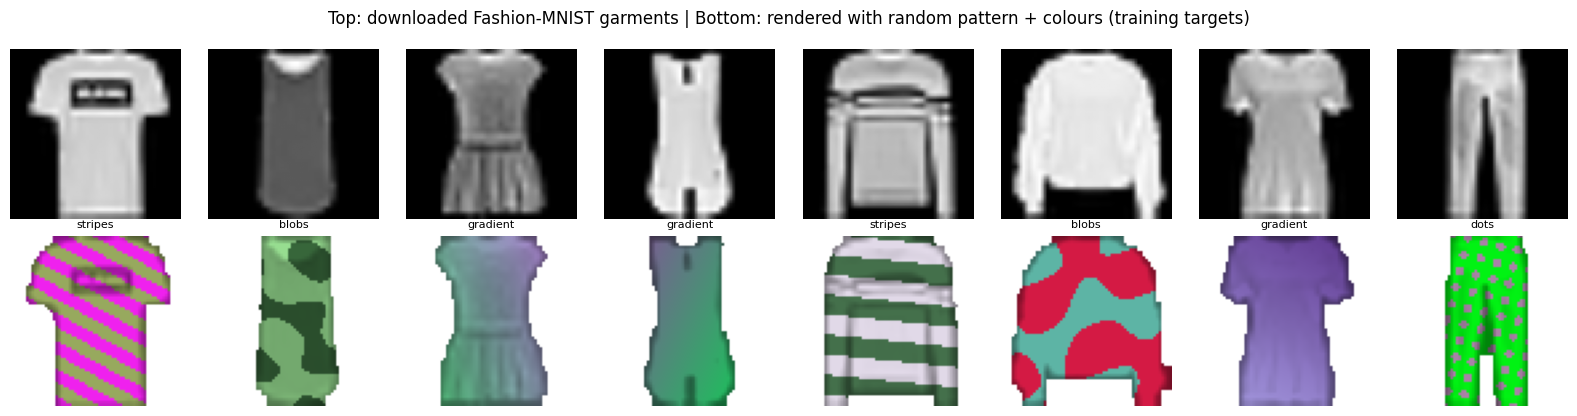

In [5]:
x_tr, y_tr, x_te, y_te = load_fashion_mnist("data")
print("train:", x_tr.shape, "test:", x_te.shape)

# keep only garments (T-shirt, trouser, pullover, dress, coat, shirt)
keep_tr = np.isin(y_tr, GARMENT_CLASSES)
keep_te = np.isin(y_te, GARMENT_CLASSES)
x_tr, x_te = x_tr[keep_tr][:N_TRAIN], x_te[keep_te]

X_train = to_gray_tensor(x_tr)      # (N,1,64,64) in [0,1]
X_test  = to_gray_tensor(x_te)
print("garments used for training:", len(X_train), "| held-out:", len(X_test))

# preview: raw garments and the same garments rendered with random patterns/colours
g = X_train[:8]; m = mask_from_gray(g); s = sample_style(8)
styled = render_styled(g, m, s)
fig, ax = plt.subplots(2, 8, figsize=(16, 4.2))
for i in range(8):
    ax[0, i].imshow(g[i, 0], cmap="gray"); ax[0, i].axis("off")
    ax[1, i].imshow(to_np(styled[i])); ax[1, i].axis("off")
    ax[1, i].set_title(describe_style(s[i])[0], fontsize=8)
ax[0, 0].set_ylabel("raw")
plt.suptitle("Top: downloaded Fashion-MNIST garments | Bottom: rendered with random pattern + colours (training targets)")
plt.tight_layout(); plt.show()

## 4) Train the GAN

Each training step:
* take a garment, render it with a random style **A** (this is the *input* picture) and a random style **B** (the *target*);
* the generator gets *(input picture, silhouette, style B)* and must output the garment in style B;
* the discriminator learns to separate real styled garments from generator outputs;
* generator loss = fool the discriminator + L1 distance to the target.

In [7]:
G = Generator().to(DEVICE); D = Discriminator().to(DEVICE)
G.apply(init_weights); D.apply(init_weights)
optG = torch.optim.Adam(G.parameters(), lr=LR, betas=(0.5, 0.999))
optD = torch.optim.Adam(D.parameters(), lr=LR, betas=(0.5, 0.999))
bce, l1 = nn.BCEWithLogitsLoss(), nn.L1Loss()

hist = {"D": [], "G": [], "L1": [], "D_real": [], "D_fake": []}

# fixed batch for visual progress
fx_gray = X_test[:6].to(DEVICE); fx_mask = mask_from_gray(fx_gray)
fx_sa, fx_sb = sample_style(6, DEVICE), sample_style(6, DEVICE)
fx_src = render_styled(fx_gray, fx_mask, fx_sa); fx_tgt = render_styled(fx_gray, fx_mask, fx_sb)

def preview(epoch):
    G.eval()
    with torch.no_grad():
        out = G(fx_src, fx_mask, fx_sb)
        sc = D.score(out).cpu()
    G.train()
    fig, ax = plt.subplots(3, 6, figsize=(13, 7))
    for i in range(6):
        for r, (im, t) in enumerate([(fx_src[i], "input"), (out[i], "generated  D=%.2f" % sc[i]), (fx_tgt[i], "target")]):
            ax[r, i].imshow(to_np(im)); ax[r, i].axis("off"); ax[r, i].set_title(t, fontsize=8)
    plt.suptitle("epoch %d" % epoch); plt.tight_layout(); plt.show()

t0 = time.time()
n = len(X_train)
for epoch in range(1, EPOCHS + 1):
    G.train(); D.train()
    perm = torch.randperm(n)
    run = {k: [] for k in hist}
    for i in range(0, n - BATCH + 1, BATCH):
        gray = X_train[perm[i:i + BATCH]].to(DEVICE)
        mask = mask_from_gray(gray)
        s_a, s_b = sample_style(BATCH, DEVICE), sample_style(BATCH, DEVICE)
        src = render_styled(gray, mask, s_a)          # what the user "uploads"
        tgt = render_styled(gray, mask, s_b)          # the real restyled garment
        fake = G(src, mask, s_b)

        # ---- discriminator ----
        d_real, d_fake = D(tgt), D(fake.detach())
        loss_D = 0.5 * (bce(d_real, torch.full_like(d_real, 0.9)) + bce(d_fake, torch.zeros_like(d_fake)))
        optD.zero_grad(); loss_D.backward(); optD.step()

        # ---- generator ----
        d_out = D(fake)
        adv = bce(d_out, torch.ones_like(d_out))
        pix = l1(fake, tgt)
        loss_G = adv + L1_W * pix
        optG.zero_grad(); loss_G.backward(); optG.step()

        run["D"].append(loss_D.item()); run["G"].append(loss_G.item()); run["L1"].append(pix.item())
        run["D_real"].append(torch.sigmoid(d_real).mean().item()); run["D_fake"].append(torch.sigmoid(d_fake).mean().item())
    for k in hist: hist[k].append(float(np.mean(run[k])))
    print("epoch %2d/%d | D %.3f | G %.3f | L1 %.3f | D(real) %.2f | D(fake) %.2f | %.0fs" % (
        epoch, EPOCHS, hist["D"][-1], hist["G"][-1], hist["L1"][-1], hist["D_real"][-1], hist["D_fake"][-1], time.time() - t0))
    if epoch == 1 or epoch % 4 == 0 or epoch == EPOCHS:
        preview(epoch)

KeyboardInterrupt: 

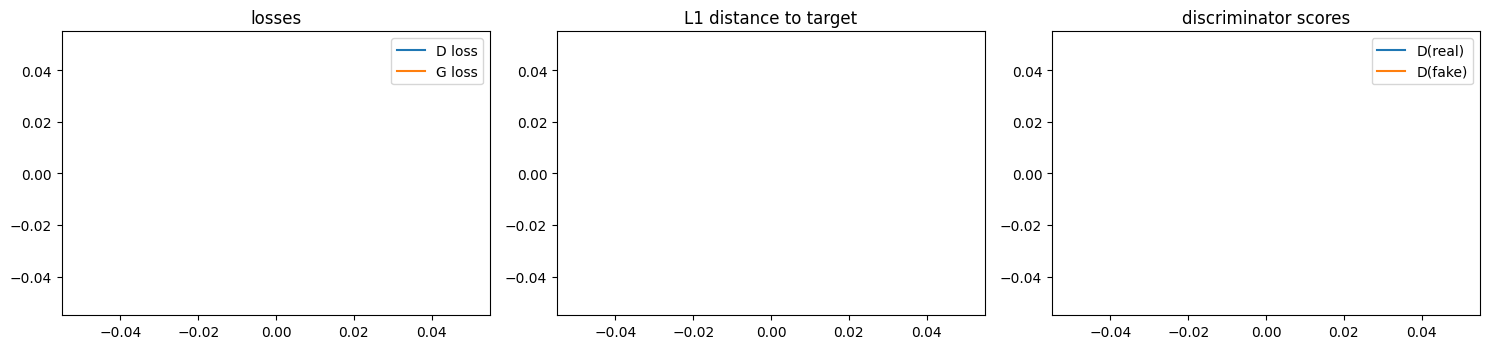

In [8]:
fig, ax = plt.subplots(1, 3, figsize=(15, 3.6))
ax[0].plot(hist["D"], label="D loss"); ax[0].plot(hist["G"], label="G loss"); ax[0].legend(); ax[0].set_title("losses")
ax[1].plot(hist["L1"]); ax[1].set_title("L1 distance to target")
ax[2].plot(hist["D_real"], label="D(real)"); ax[2].plot(hist["D_fake"], label="D(fake)"); ax[2].legend(); ax[2].set_title("discriminator scores")
plt.tight_layout(); plt.show()

## 5) Discriminator score: real vs generated

`D.score(image)` returns a value in 0..1 (≈1 = looks real, ≈0 = looks generated). We measure it on **held-out** garments and pick the threshold that best separates real from generated images, then save everything.

mean score  real: 0.553 | generated: 0.572
threshold = 0.665 -> balanced accuracy 54.8%  (50% = generator fully fools the discriminator)


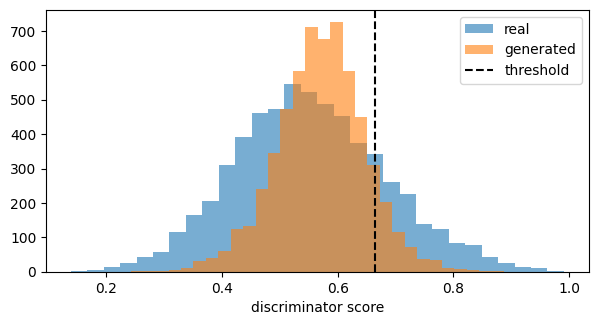

saved -> checkpoints/gan.pt


In [9]:
G.eval(); D.eval()
real_s, fake_s = [], []
with torch.no_grad():
    for i in range(0, len(X_test), BATCH):
        gray = X_test[i:i + BATCH].to(DEVICE); mask = mask_from_gray(gray)
        sa, sb = sample_style(len(gray), DEVICE), sample_style(len(gray), DEVICE)
        src = render_styled(gray, mask, sa); tgt = render_styled(gray, mask, sb)
        real_s += D.score(tgt).cpu().tolist()
        fake_s += D.score(G(src, mask, sb)).cpu().tolist()
real_s, fake_s = np.array(real_s), np.array(fake_s)
THRESH, ACC = best_threshold(real_s, fake_s)
print("mean score  real: %.3f | generated: %.3f" % (real_s.mean(), fake_s.mean()))
print("threshold = %.3f -> balanced accuracy %.1f%%  (50%% = generator fully fools the discriminator)" % (THRESH, ACC * 100))

plt.figure(figsize=(7, 3.4))
plt.hist(real_s, bins=30, alpha=.6, label="real"); plt.hist(fake_s, bins=30, alpha=.6, label="generated")
plt.axvline(THRESH, color="k", ls="--", label="threshold"); plt.xlabel("discriminator score"); plt.legend(); plt.show()

torch.save({"G": G.state_dict(), "D": D.state_dict(), "threshold": THRESH, "balanced_acc": ACC, "img": IMG}, CKPT)
print("saved ->", CKPT)

## 6) Try it: give a clothing image, get restyled variants + scores
Set `INPUT_PATH` to your own image (a garment on a plain background works best). If it does not exist, a sample garment from the downloaded dataset is used.

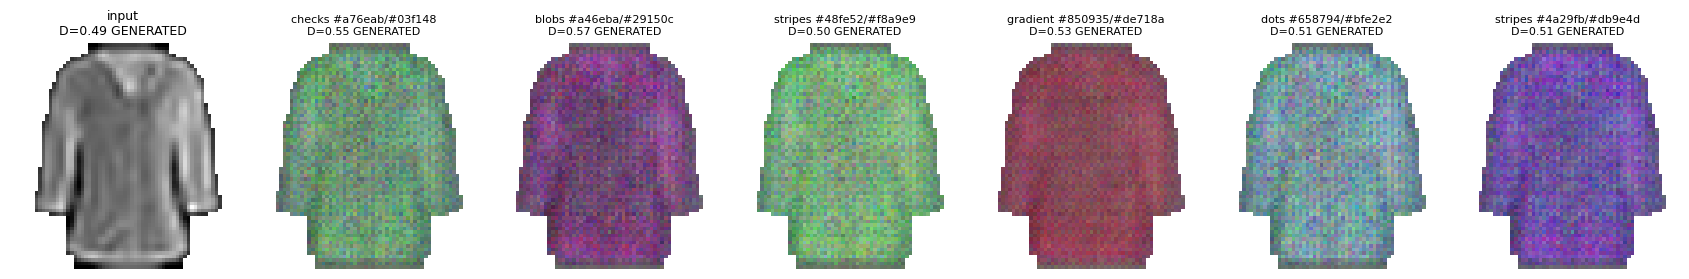

In [10]:
import PIL
from PIL import Image
INPUT_PATH = "my_clothing.jpg"      # <- put your own file here

if not os.path.exists(INPUT_PATH):
    INPUT_PATH = "sample_input.png"
    Image.fromarray(x_te[3]).resize((256, 256), Image.BICUBIC).save(INPUT_PATH)
pil = Image.open(INPUT_PATH)

src, outs, styles, scores, src_score = generate_variants(G, D, pil, n=6, device=DEVICE)
fig, ax = plt.subplots(1, 7, figsize=(17, 3.4))
ax[0].imshow(to_np(src)); ax[0].set_title("input\nD=%.2f %s" % (src_score, verdict(src_score, THRESH)), fontsize=9); ax[0].axis("off")
for i in range(6):
    name, c1, c2 = describe_style(styles[i])
    ax[i + 1].imshow(to_np(outs[i])); ax[i + 1].axis("off")
    ax[i + 1].set_title("%s %s/%s\nD=%.2f %s" % (name, c1, c2, scores[i], verdict(scores[i], THRESH)), fontsize=8)
plt.tight_layout(); plt.show()

In [11]:
import PIL
from PIL import Image

print(Image)
print("Pillow imported successfully")

<module 'PIL.Image' from 'c:\\Users\\KIIT0001\\AppData\\Local\\Programs\\Python\\Python311\\Lib\\site-packages\\PIL\\Image.py'>
Pillow imported successfully


## 7) Local web app (Flask)
This cell writes `app.py`. It loads `checkpoints/gan.pt`, lets you upload a clothing picture, choose a pattern / colours (or random), and shows each generated design with its **discriminator score and REAL/GENERATED verdict**.

In [12]:
%%writefile app.py
import base64, io, os, sys

import torch
from flask import Flask, render_template_string, request
from PIL import Image

from gan_core import (Generator, Discriminator, PATTERNS, generate_variants, describe_style,
                      to_pil, verdict)

DEVICE = "cuda" if torch.cuda.is_available() else "cpu"
CKPT = os.environ.get("CKPT", "checkpoints/gan.pt")
if not os.path.exists(CKPT):
    sys.exit("Checkpoint %s not found. Run the training cells in the notebook first." % CKPT)

ck = torch.load(CKPT, map_location=DEVICE)
G = Generator().to(DEVICE); G.load_state_dict(ck["G"]); G.eval()
D = Discriminator().to(DEVICE); D.load_state_dict(ck["D"]); D.eval()
THRESH = float(ck["threshold"])

app = Flask(__name__)
app.config["MAX_CONTENT_LENGTH"] = 16 * 1024 * 1024

PAGE = """
<!doctype html>
<html><head><meta charset="utf-8"><title>Clothing Restyle GAN</title>
<style>
 body{font-family:system-ui,sans-serif;margin:0;background:#f4f4f6;color:#222}
 header{background:#222;color:#fff;padding:16px 28px}
 main{max-width:1100px;margin:auto;padding:24px}
 form{background:#fff;padding:18px;border-radius:10px;display:flex;flex-wrap:wrap;gap:16px;align-items:end}
 label{font-size:13px;display:flex;flex-direction:column;gap:4px}
 button{background:#4c3fe0;color:#fff;border:0;padding:10px 22px;border-radius:8px;font-size:15px;cursor:pointer}
 .grid{display:grid;grid-template-columns:repeat(auto-fill,minmax(210px,1fr));gap:16px;margin-top:22px}
 .card{background:#fff;border-radius:10px;padding:10px;text-align:center;box-shadow:0 1px 3px rgba(0,0,0,.08)}
 .card img{width:100%;border-radius:6px;image-rendering:auto}
 .tag{display:inline-block;padding:2px 10px;border-radius:12px;font-size:12px;font-weight:600;color:#fff}
 .real{background:#1e9d57}.gen{background:#d6453d}
 .sw{display:inline-block;width:14px;height:14px;border-radius:3px;vertical-align:middle;border:1px solid #ccc}
 .bar{height:8px;background:#e3e3e8;border-radius:4px;margin:6px 0;overflow:hidden}
 .bar>div{height:100%;background:#4c3fe0}
 .err{color:#b00020;margin-top:12px}
 small{color:#666}
</style></head><body>
<header><h2 style="margin:0">Clothing Restyle GAN</h2>
<small style="color:#bbb">Upload a garment, get new patterns and colours. Discriminator threshold: {{ '%.2f' % thresh }}</small></header>
<main>
<form method="post" enctype="multipart/form-data">
 <label>Clothing image<input type="file" name="image" accept="image/*" required></label>
 <label>Variants<input type="number" name="count" value="6" min="1" max="12" style="width:70px"></label>
 <label>Pattern<select name="pattern"><option value="random">random</option>
  {% for p in patterns %}<option value="{{p}}">{{p}}</option>{% endfor %}</select></label>
 <label><span><input type="checkbox" name="use_colors"> use my colours</span>
  <span><input type="color" name="color1" value="#c0392b"> <input type="color" name="color2" value="#f4d03f"></span></label>
 <button type="submit">Generate</button>
</form>
{% if error %}<div class="err">{{ error }}</div>{% endif %}
{% if results %}
 <h3>Input</h3>
 <div class="grid"><div class="card"><img src="{{ source.img }}">
   <div class="bar"><div style="width:{{ source.pct }}%"></div></div>
   D score {{ '%.3f' % source.score }} <span class="tag {{ 'real' if source.verdict=='REAL' else 'gen' }}">{{ source.verdict }}</span></div></div>
 <h3>Generated designs</h3>
 <div class="grid">
 {% for r in results %}
  <div class="card"><img src="{{ r.img }}">
   <div style="margin-top:6px">{{ r.pattern }}
    <span class="sw" style="background:{{ r.c1 }}"></span><span class="sw" style="background:{{ r.c2 }}"></span></div>
   <div class="bar"><div style="width:{{ r.pct }}%"></div></div>
   D score {{ '%.3f' % r.score }} <span class="tag {{ 'real' if r.verdict=='REAL' else 'gen' }}">{{ r.verdict }}</span>
  </div>
 {% endfor %}</div>
 <p><small>Score = discriminator's probability that the image is a real (dataset-style) garment. A GAN generator is trained to fool this score,
 so GENERATED verdicts become rarer as training improves.</small></p>
{% endif %}
</main></body></html>
"""


def b64(t):
    buf = io.BytesIO()
    to_pil(t).save(buf, format="PNG")
    return "data:image/png;base64," + base64.b64encode(buf.getvalue()).decode()


def hex_to_rgb(h):
    h = h.lstrip("#")
    return tuple(int(h[i:i + 2], 16) / 255.0 for i in (0, 2, 4))


@app.route("/", methods=["GET", "POST"])
def index():
    results, source, error = None, None, None
    if request.method == "POST":
        f = request.files.get("image")
        try:
            if f is None or f.filename == "":
                raise ValueError("Please choose an image.")
            img = Image.open(f.stream)
            n = max(1, min(12, int(request.form.get("count", 6))))
            pat = request.form.get("pattern", "random")
            pat = None if pat == "random" else PATTERNS.index(pat)
            colors = None
            if request.form.get("use_colors"):
                colors = (hex_to_rgb(request.form["color1"]), hex_to_rgb(request.form["color2"]))
            src, outs, styles, scores, src_score = generate_variants(G, D, img, n=n, pattern=pat,
                                                                      colors=colors, device=DEVICE)
            source = dict(img=b64(src), score=src_score, pct=int(src_score * 100), verdict=verdict(src_score, THRESH))
            results = []
            for i in range(n):
                name, c1, c2 = describe_style(styles[i])
                results.append(dict(img=b64(outs[i]), pattern=name, c1=c1, c2=c2, score=scores[i],
                                    pct=int(scores[i] * 100), verdict=verdict(scores[i], THRESH)))
        except Exception as e:
            error = "Could not process the image: %s" % e
    return render_template_string(PAGE, results=results, source=source, error=error,
                                  patterns=PATTERNS, thresh=THRESH)


if __name__ == "__main__":
    port = int(os.environ.get("PORT", 5000))
    print("Open http://127.0.0.1:%d" % port)
    app.run(host="127.0.0.1", port=port, debug=False)

Overwriting app.py


In [14]:
# Start the local app in the background, then open http://127.0.0.1:5000 in your browser
APP_PORT = 5000
app_proc = subprocess.Popen([sys.executable, "app.py"], env={**os.environ, "PORT": str(APP_PORT)})
time.sleep(6)
print("App running -> http://127.0.0.1:%d   (stop it with the next cell)" % APP_PORT)

App running -> http://127.0.0.1:5000   (stop it with the next cell)


In [ ]:
# Stop the web app
app_proc.terminate()
print("stopped")
# You can also run it from a terminal any time later:  python app.py

stopped


## Notes
* **Data**: clothing silhouettes/shading come from Fashion-MNIST downloaded at run time; the **patterns and colours** are rendered procedurally (stripes, checks, dots, zig-zag, gradient, blobs). The generator therefore learns to restyle any garment into any of those designs.
* **Real photos**: uploaded photos work best when the garment is on a plain background. The model is trained on small 64x64 catalogue-style images, so photos of folds/textures will be simplified.
* **Discriminator score**: "real" means *looks like the training distribution*; it is not a general fake-image detector.
* For better quality: raise `EPOCHS`, `N_TRAIN`, or add more pattern types in `pattern_mix` inside `gan_core.py`.